# Faz 01 — Keşifsel Veri Analizi (EDA)

## Kurulum

İhtiyaç duyacağın kütüphaneleri içe aktar.

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


---
## 1. Veriyi Yükle ve İlk Bakış

Veriyi yükle. Ardından şu soruları yanıtla:
- Kaç satır, kaç sütun var?
- Sütunların veri tipleri neler?
- İlk birkaç satır nasıl görünüyor?

In [5]:
#veri yükleme
data = pd.read_csv('../data/raw/train.csv')
#kaç satır ve sütun olduğunu gösterir
print(f"Dataset shape: {data.shape}")

Dataset shape: (577347, 12)


In [6]:
#sütünların veri tiplerini gösterir
print(data.dtypes)

id                     int64
alpha                float64
delta                float64
u                    float64
g                    float64
r                    float64
i                    float64
z                    float64
redshift             float64
spectral_type         object
galaxy_population     object
class                 object
dtype: object


In [7]:
#ilk 5 satırı gösterir
print(data.head())

   id       alpha      delta          u          g          r          i  \
0   0  147.734256  16.959273  25.472123  21.895559  20.357926  19.257113   
1   1  127.988677  32.346716  20.778509  19.087062  17.587208  17.226067   
2   2  179.792648  35.344843  21.035203  21.079128  21.171840  20.582629   
3   3  225.818295  48.569421  23.305056  21.050736  19.017754  18.365658   
4   4  141.836135  19.342852  21.703158  19.471680  18.234449  17.899447   

           z  redshift spectral_type galaxy_population   class  
0  18.621057  0.408982             M      Red_Sequence  GALAXY  
1  16.786433  0.157976             M      Red_Sequence  GALAXY  
2  20.557366  2.823770           O/B        Blue_Cloud     QSO  
3  17.914952  0.536099             M      Red_Sequence  GALAXY  
4  17.616185  0.555761             M      Red_Sequence  GALAXY  


---
## 2. Sınıf Dağılımı

Hedef sütun (`class`) nasıl dağılmış?
- Her sınıftan kaç örnek var?
- Dağılımı görselleştir.
- Balanced Accuracy metriği açısından bu dağılım ne anlama geliyor?

In [9]:
#Her sınıftan kaç örnek var
print(data['class'].value_counts())

class
GALAXY    377480
QSO       117143
STAR       82724
Name: count, dtype: int64


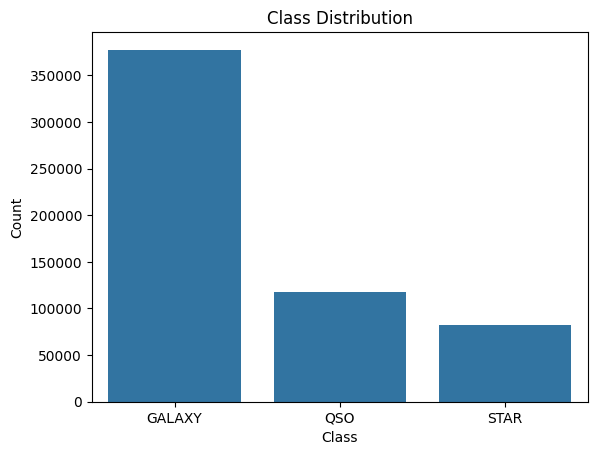

In [10]:
#Dağılım grafiği
sns.countplot(x='class', data=data)
plt.title('Class Distribution')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

**Yorumun:** *(Buraya yaz)*

---
## 3. Eksik Değerler ve Veri Kalitesi

- Herhangi bir sütunda eksik değer var mı?
- Sayısal sütunların istatistiksel özeti nasıl? (min, max, ortalama, standart sapma)
- Gözle görülür aykırı değer var mı?

In [11]:
#eksik değerlerin sayısını gösterir
print(data.isnull().sum())

id                   0
alpha                0
delta                0
u                    0
g                    0
r                    0
i                    0
z                    0
redshift             0
spectral_type        0
galaxy_population    0
class                0
dtype: int64


In [12]:
# Summary statistics
print(data.describe())

                 id          alpha          delta              u  \
count  577347.00000  577347.000000  577347.000000  577347.000000   
mean   288673.00000     181.616673      21.834654      22.441926   
std    166665.86727      96.242941      18.933570       2.018135   
min         0.00000       0.011684     -17.966988      -0.139225   
25%    144336.50000     132.161499       2.474097      20.977090   
50%    288673.00000     188.681465      21.484412      22.570222   
75%    433009.50000     231.829693      36.988310      23.869103   
max    577346.00000     359.999810      79.158322      28.253263   

                   g              r              i              z  \
count  577347.000000  577347.000000  577347.000000  577347.000000   
mean       21.007273      19.962811      19.378911      19.041136   
std         1.795426       1.648964       1.580059       1.584365   
min        13.535483      12.579407      11.962781      11.682803   
25%        19.865005      18.820671      1

**Yorumun:** *(Buraya yaz)*

---
## 4. Redshift Analizi

Faz 00'da redshift'in sınıfları güçlü ayırdığını öğrenmiştin. Veri bunu doğruluyor mu?
- Her sınıf için redshift dağılımını görselleştir.
- Sınıflar arasındaki fark ne kadar belirgin?

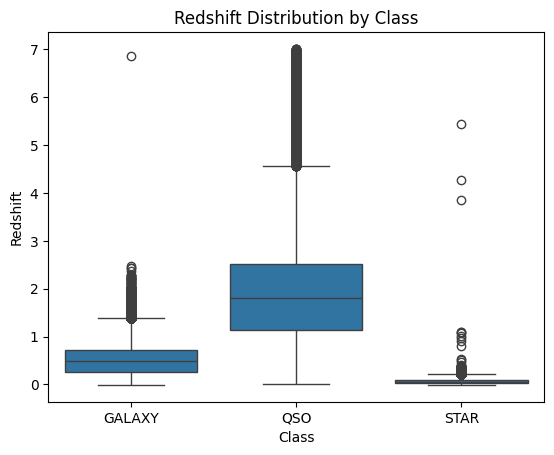

In [13]:
#her sınıf için redshift dağılımı
sns.boxplot(x='class', y='redshift', data=data)
plt.title('Redshift Distribution by Class')
plt.xlabel('Class')
plt.ylabel('Redshift')
plt.show()

In [14]:
#sınıflar arasındaki korelasyonu gösterir
correlation_matrix = data.corr()
plt.figure(figsize=(12, 10))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Correlation Matrix')
plt.show()
#sınıflar arası farklılıkları gösterir
sns.pairplot(data, hue='class')
plt.show()

ValueError: could not convert string to float: 'M'

**Yorumun:** *(Buraya yaz)*

---
## 5. Fotometrik Filtreler: u, g, r, i, z

- Her filtre için sınıf bazında dağılımları görselleştir.
- Hangi filtre sınıfları en iyi ayırıyor?
- Dağılımlar simetrik mi, çarpık mı?

**Yorumun:** *(Buraya yaz)*

---
## 6. Korelasyon Analizi

- Sayısal feature'lar arasındaki korelasyonu görselleştir.
- Birbirine yüksek oranda bağımlı feature çifti var mı?
- Bu, model için ne anlama gelebilir?

**Yorumun:** *(Buraya yaz)*

---
## 7. ID Sütunları — Atılacak mı, Tutulacak mı?

`run_ID`, `cam_col`, `plate`, `MJD`, `fiber_ID` gibi sütunlar modele anlamlı bilgi katıyor mu?
- Bu sütunların sınıflarla ilişkisi var mı?
- Yoksa bunlar sadece gözlemin kimliği mi?

**Yorumun:** *(Buraya yaz)*

---
## 8. EDA Özeti — Modellemeye Taşıyacakların

Bu bölümü son olarak doldur. Bir sonraki fazda ne yapacağını şimdiden belirle:

**Kullanacağım feature'lar:**

*(yaz)*

**Düşüreceğim sütunlar ve nedenleri:**

*(yaz)*

**Dikkat etmem gereken veri kalitesi sorunları:**

*(yaz)*

**Özellik mühendisliği için ilk fikirler (Faz 03 için not):**

*(yaz)*